In [2]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import os


def plot_csv_columns(file_paths):
    """Reads multiple CSV files and plots shared columns together.

    Each numeric column gets one subplot. If a column exists in multiple
    files, all corresponding curves are plotted in the same subplot.
    """

    # 1. Load all CSV files
    dataframes = {}

    for file_path in file_paths:
        df = pd.read_csv(file_path)
        dataframes[file_path] = df

    # 2. Get the union of all numeric columns
    all_numeric_cols = set()

    for df in dataframes.values():
        numeric_cols = df.select_dtypes(include="number").columns
        all_numeric_cols.update(numeric_cols)

    all_numeric_cols = sorted(all_numeric_cols)
    num_cols = len(all_numeric_cols)

    if num_cols == 0:
        print("No numeric columns found in the CSV files to plot.")
        return

    # 3. Determine grid dimensions
    ncols = 6 if num_cols >= 6 else num_cols
    nrows = math.ceil(num_cols / ncols)

    # 4. Create figure and subplots
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(5 * ncols, 4 * nrows),
        squeeze=False,
    )

    axes_flat = axes.flatten()

    # 5. Plot each column
    for i, col in enumerate(all_numeric_cols):
        ax = axes_flat[i]

        for file_path, df in dataframes.items():
            if col in df.columns:
                ax.plot(
                    df[col],
                    marker="o",
                    linestyle="-",
                    markersize=3,
                    label=os.path.basename(file_path),
                )

        ax.set_title(col, fontsize=11, fontweight="bold")
        ax.set_xlabel("Index", fontsize=9)
        ax.set_ylabel("Value", fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend()
        # ax.set_yscale('log')

    # 6. Hide unused subplots
    for j in range(num_cols, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    # 7. Adjust layout
    plt.suptitle(
        "Overview of Columns Across CSV Files",
        fontsize=14,
        fontweight="bold",
        y=1.02,
    )

    plt.tight_layout()
    # plt.savefig('figures/tmp.png')
    plt.show()

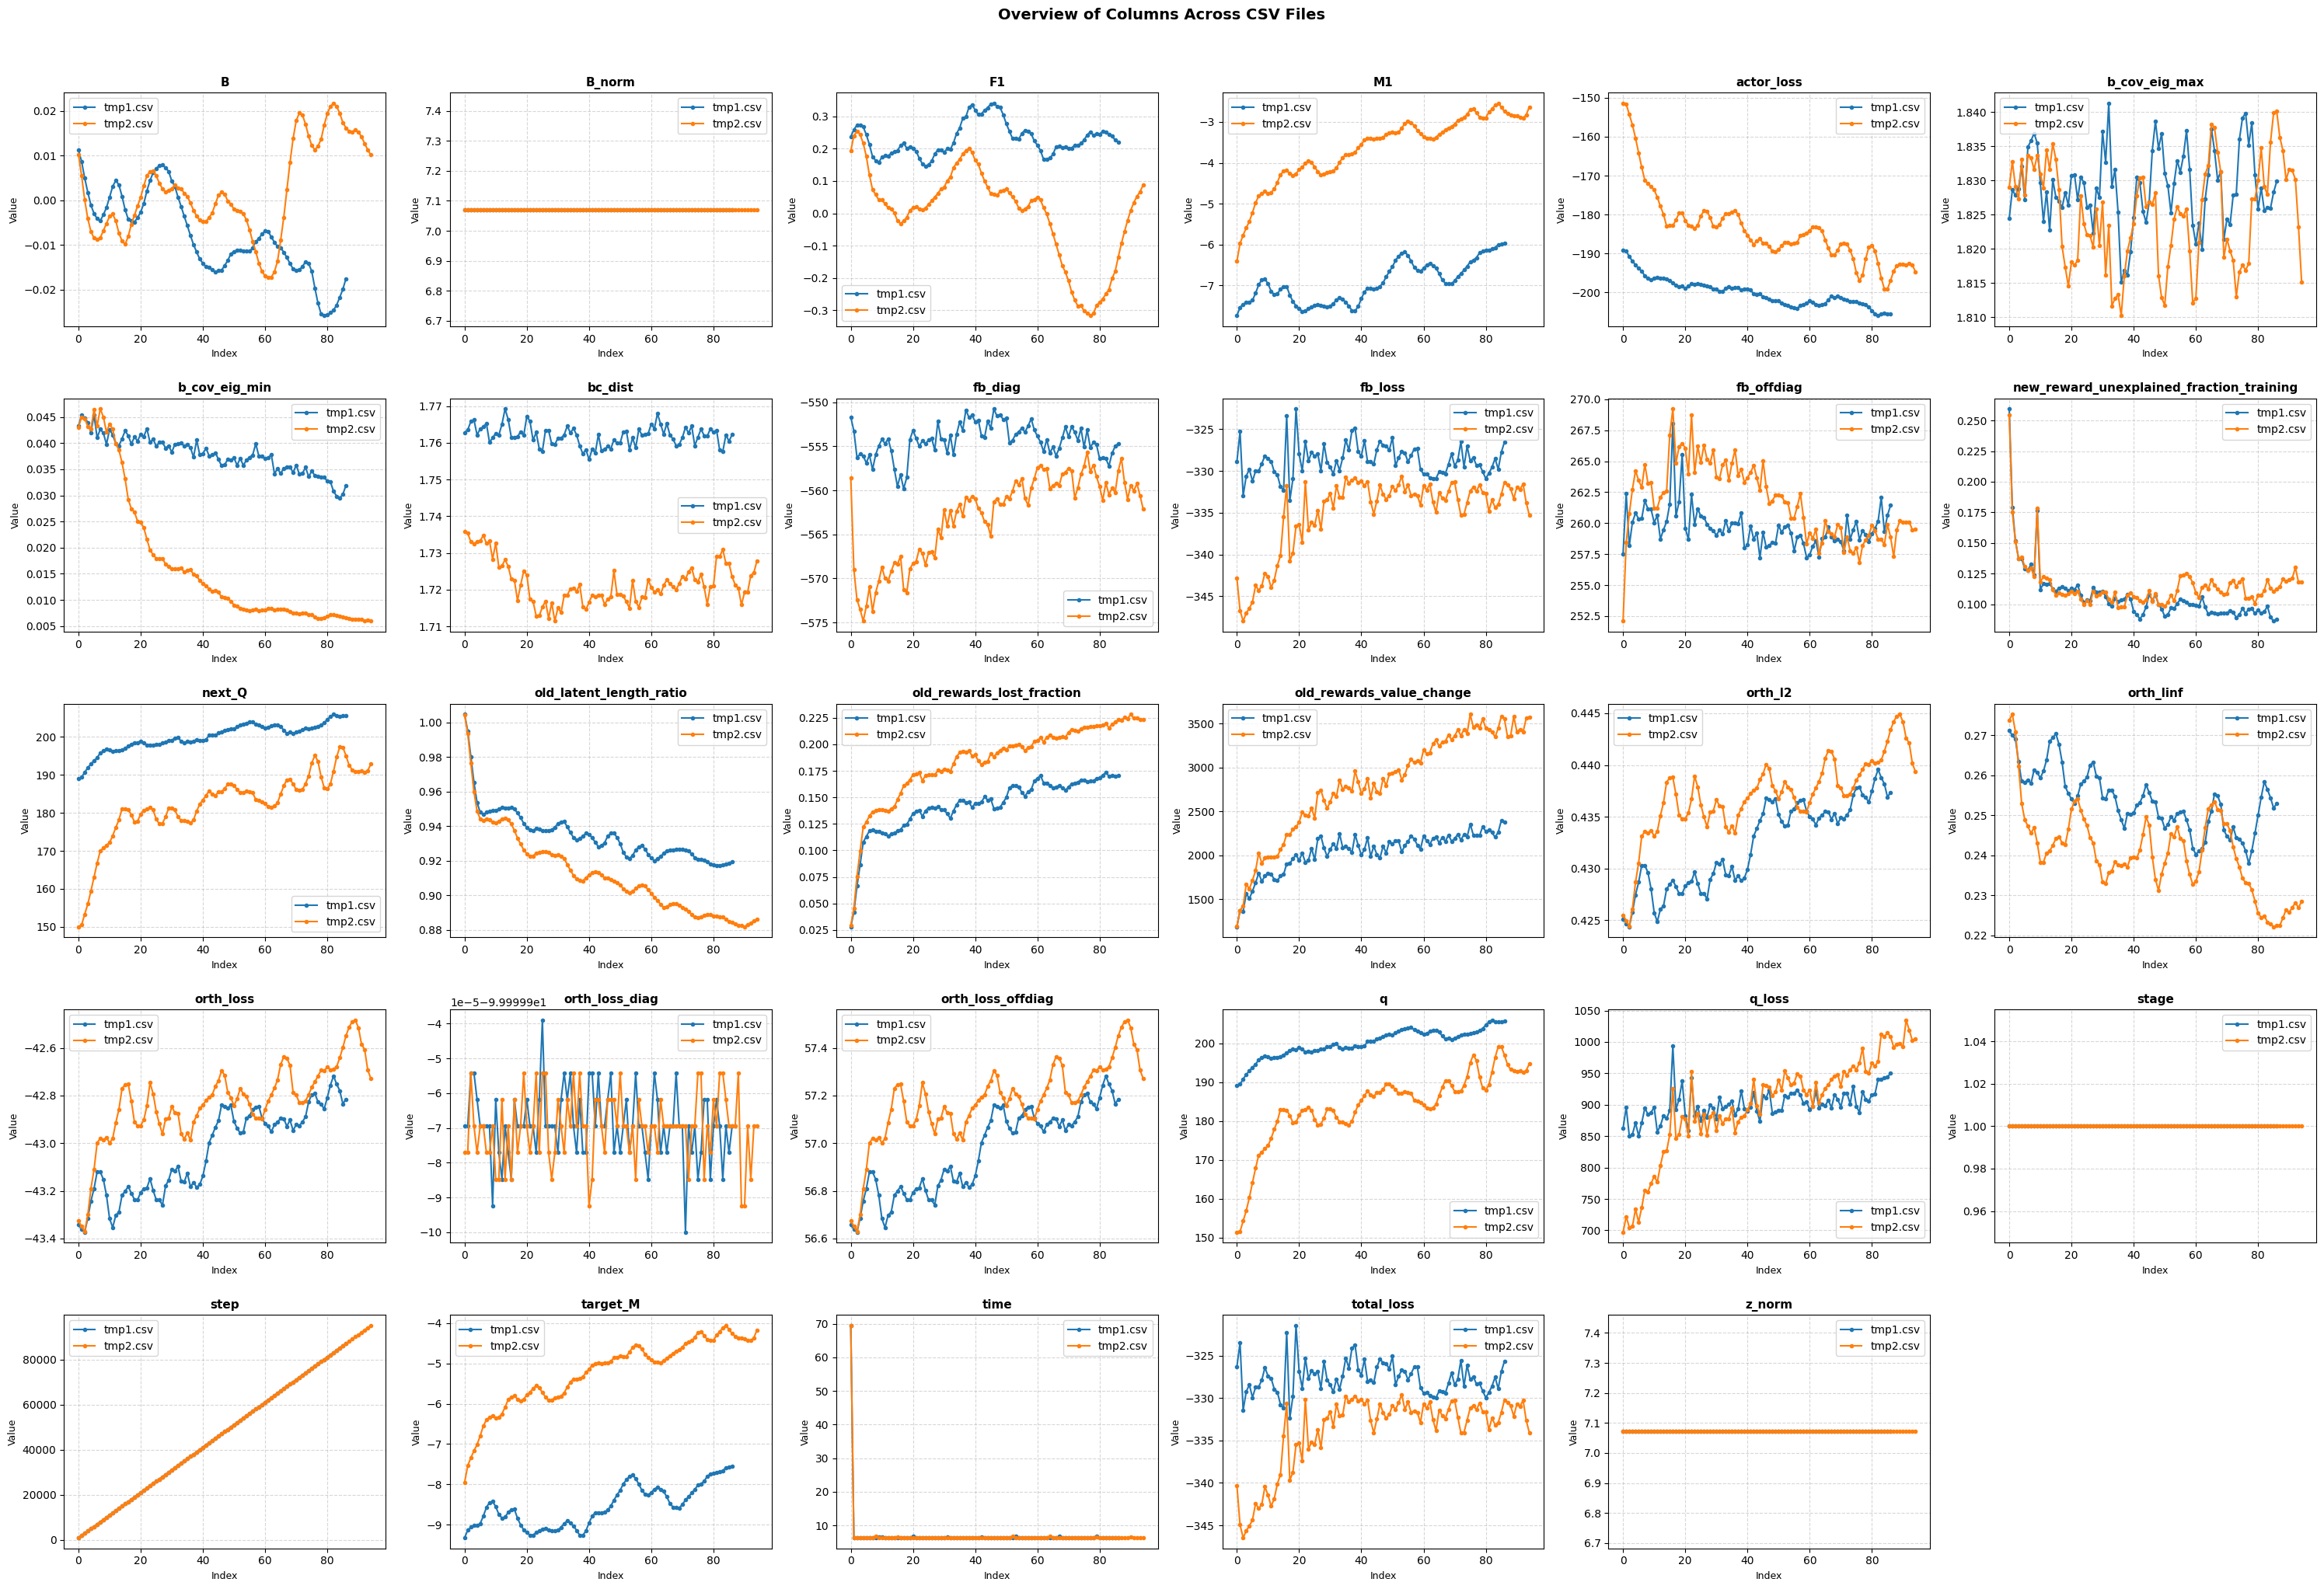

In [32]:
plot_csv_columns([
    "csv_files/tmp1.csv",
    "csv_files/tmp2.csv",
    # "csv_files/tmp3.csv",
    # "csv_files/tmp4.csv",
    # "csv_files/tmp5.csv",
    # "csv_files/tmp6.csv",
])

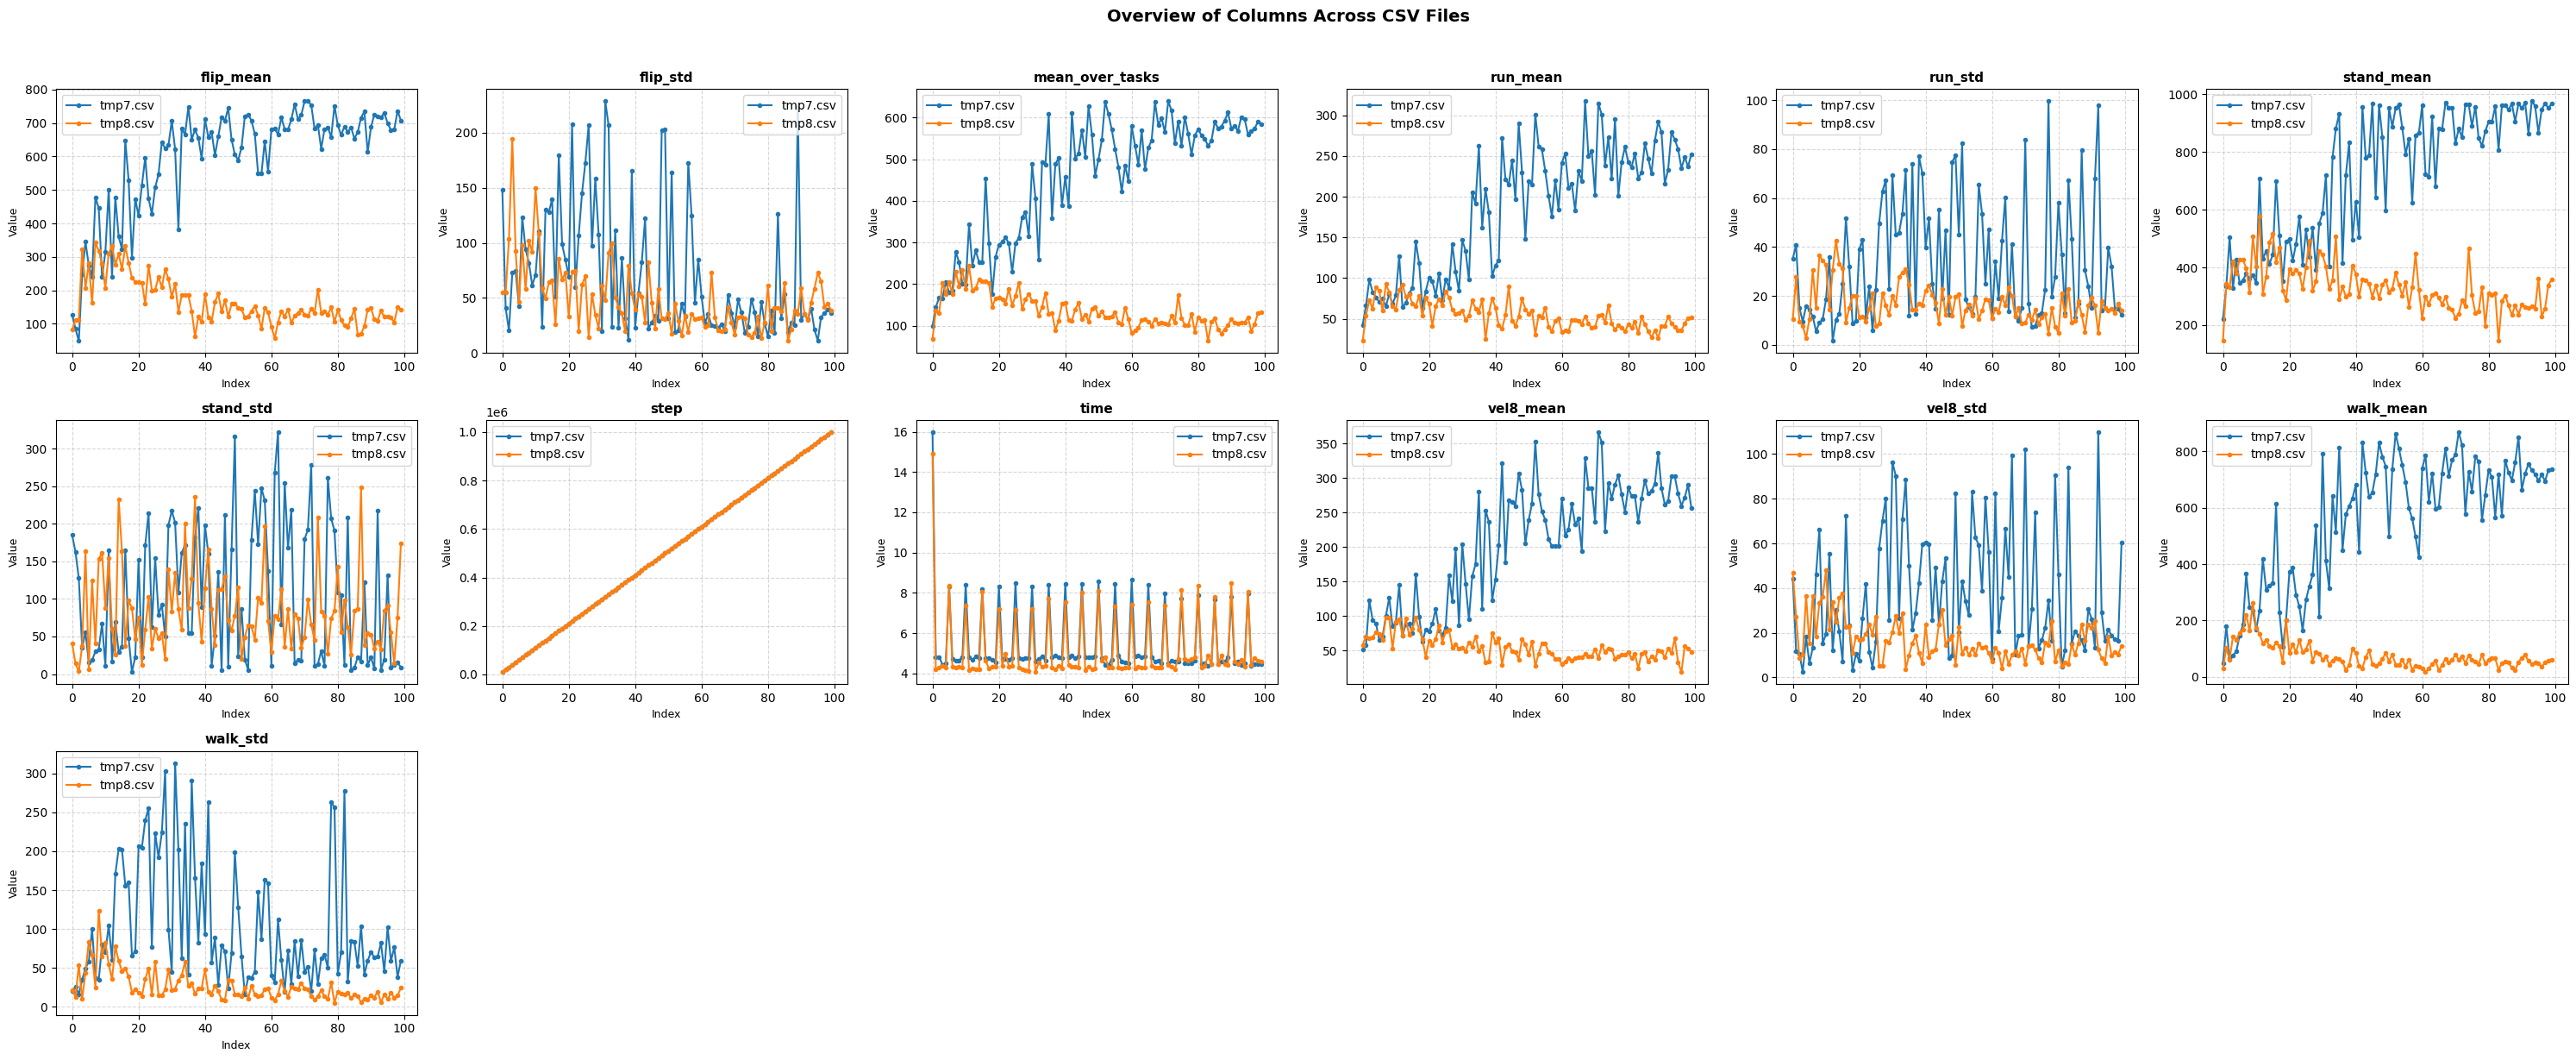

In [3]:
plot_csv_columns([
    "csv_files/tmp7.csv",
    "csv_files/tmp8.csv",
])

In [ ]:
"""

tmp1.csv classic 10M
tmp2.csv classic 1M
tmp3.csv classic 0.1M
tmp4.csv implicit 10M
tmp5.csv implicit 1M
tmp6.csv implicit 0.1M

"""

In [ ]:
import numpy as np

In [ ]:
# 838 307 538

In [23]:
print(np.mean([ 945, 935, 746, 537, 757, 753 ]))
print(np.mean([ 645, 386, 515, 463, 663, 684 ]))
print(np.mean([ 483, 276, 285, 367, 480 ]))
print(np.mean([ 638, 528, 655, 650, 545, 658 ]))

778.8333333333334
559.3333333333334
378.2
612.3333333333334
